In [30]:
from ModelSimlink import RadiativeTransitions, Levels
from standard_imports import *
from loaders import index
from plots import adv_plt, splt, interactive
from scipy.optimize import curve_fit
from Tools import LinesManipulator

In [31]:
data = index.load_index_and_data( "TestData/RfPen/20230620" ) + index.load_index_and_data( "TestData/PlasmaBIC/20241031" )
data = [ data[4], data[12] ]

Avantes spectrum TestData/RfPen/20230620\New Experiment0005.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0006.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0007.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0008.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0013.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0014.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0015.Raw8 normalized by a factor of 0.200000 s
Avantes spectrum TestData/RfPen/20230620\New Experiment0016.Raw8 normalized by a factor of 0.200000 s
8 rows loaded
Avantes spectrum TestData/PlasmaBIC/20241031\101_6us.RAW8 normalized by a factor of 0.400000 s
Avantes spectrum TestData/PlasmaBIC/20241031\102_6us.RAW8 normalized by a f

In [32]:
calib_base = pd.read_csv('CalibrationData/Calib_20250204_FCUVIR600.csv', index_col = False).to_dict('list')

In [33]:
worker = LinesManipulator.LinesManipulator()

Realigned with y = -0.00x^2 +1.00x -0.18
Realigned with y = 0.00x^2 +1.00x +0.90


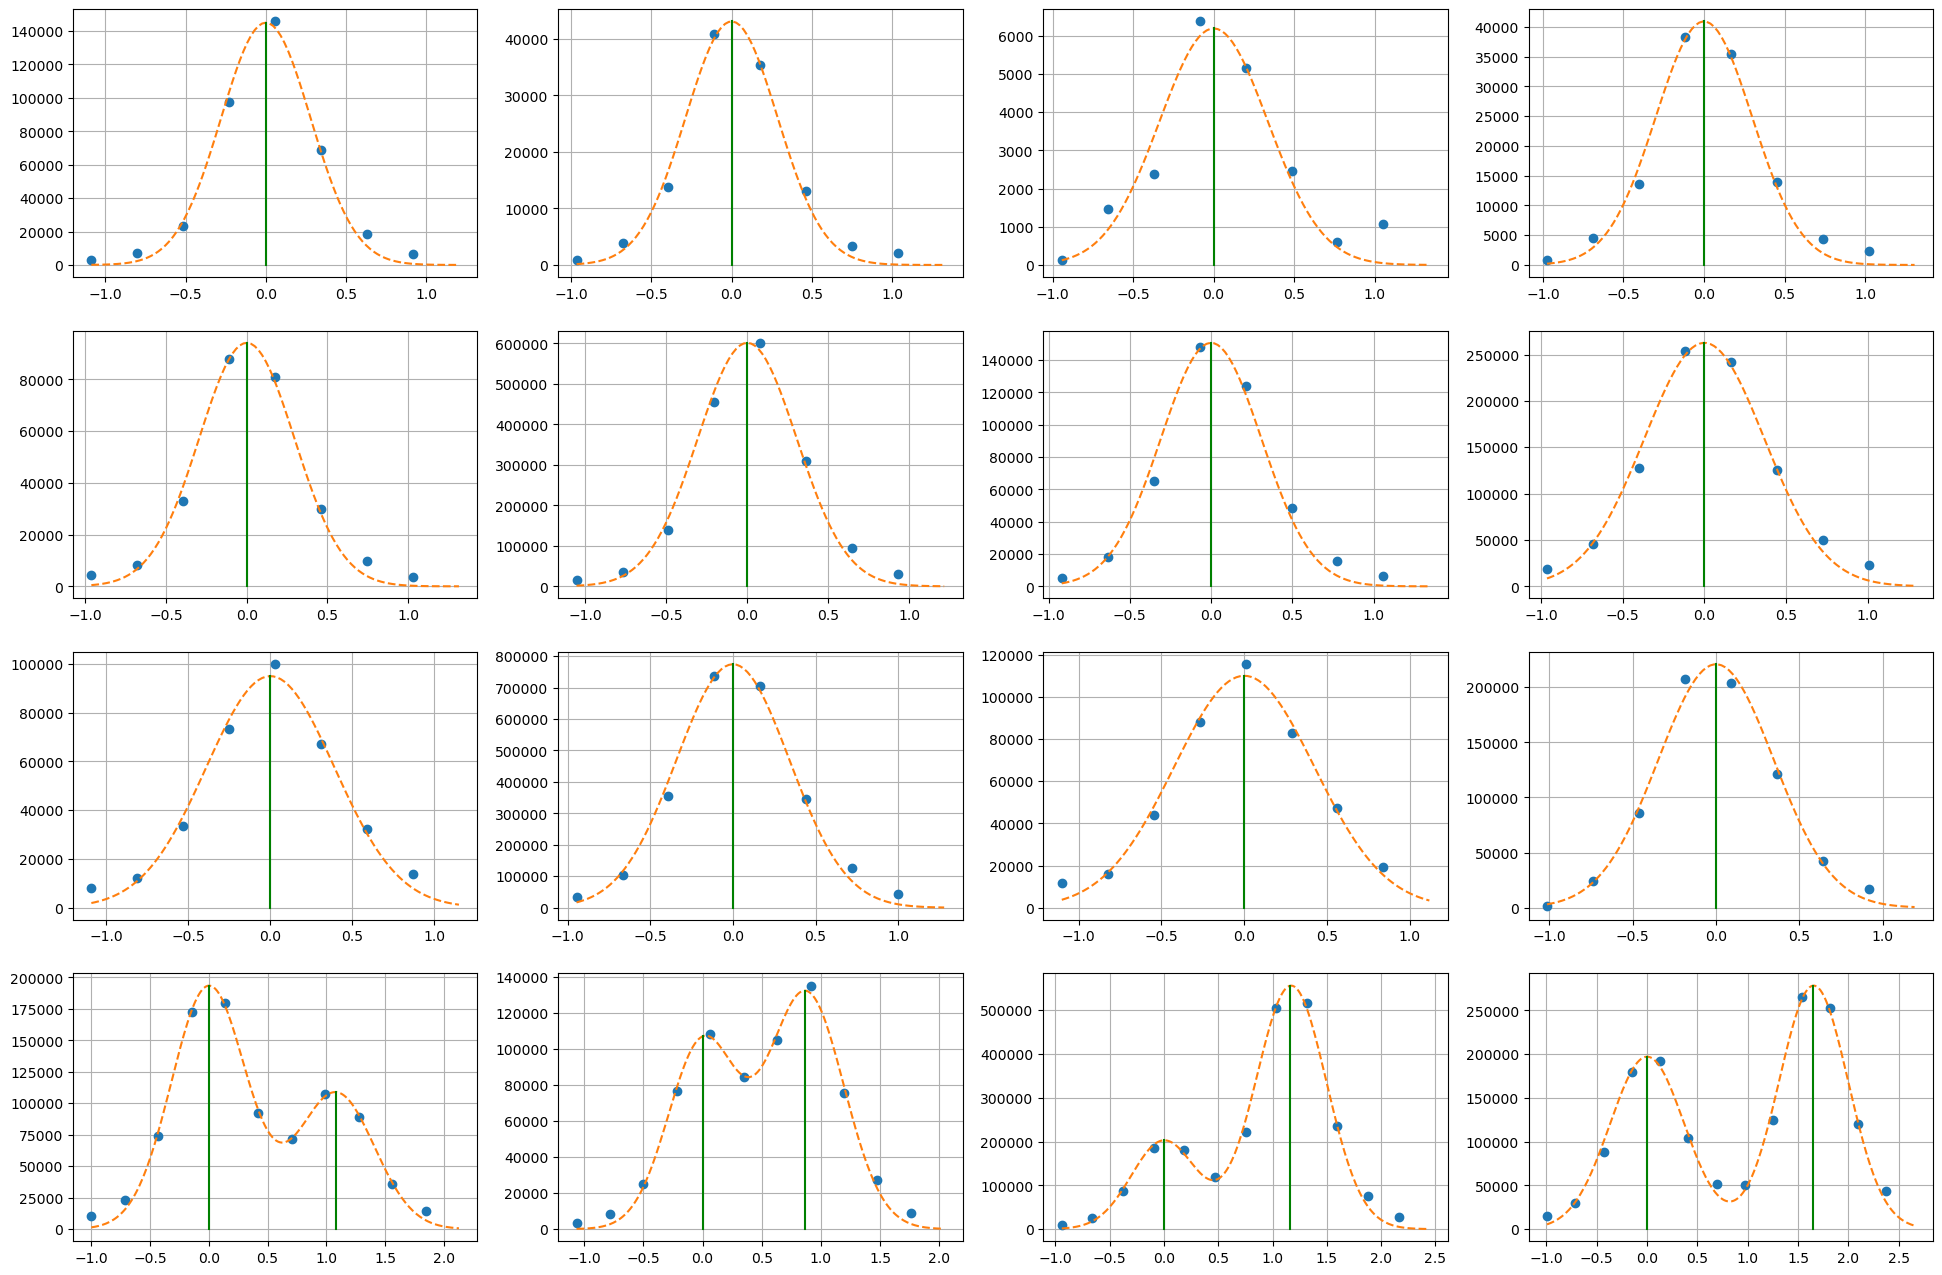

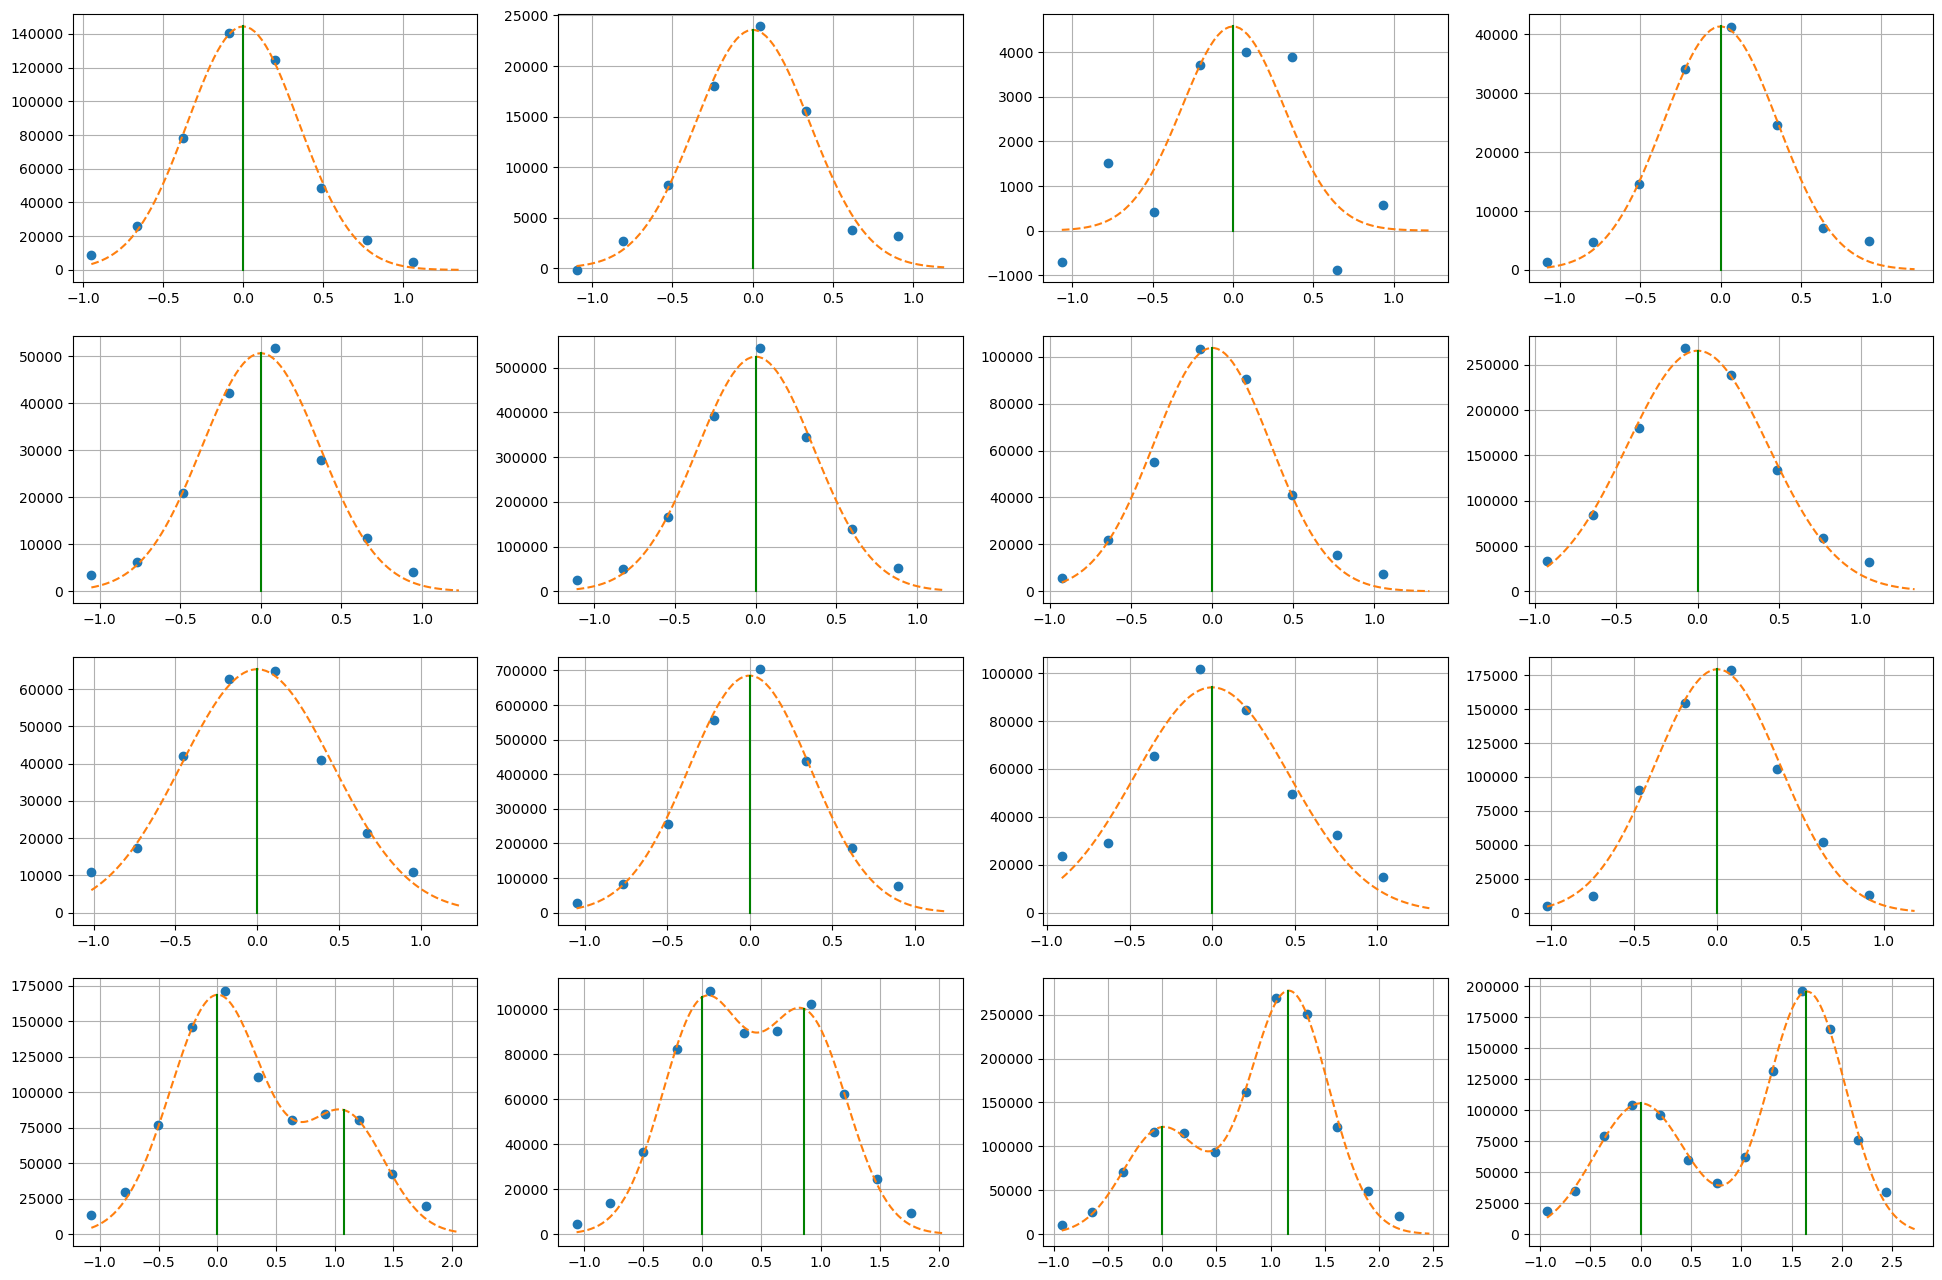

In [51]:
for d in data:
        d['wl_realigned'] = worker.realign_wl( d['avantes']['wl'], d['avantes']['int'] )
        d['int_withoutbaseline'] = worker.remove_baseline( d['avantes']['int'] )
        d['cal'] = worker.estimate_calibration( d['wl_realigned'], d['int_withoutbaseline'], calib_base, all_lines = RadiativeTransitions.RadiativeTransitions().linesList() )
        d['int_calibrated'] = d['cal']['int_calib']
        d['densities'] = worker.estimate_densities( d['wl_realigned'], d['int_calibrated'], RadiativeTransitions.RadiativeTransitions().linesList(), plot = True )

In [35]:
lv = Levels.Levels()

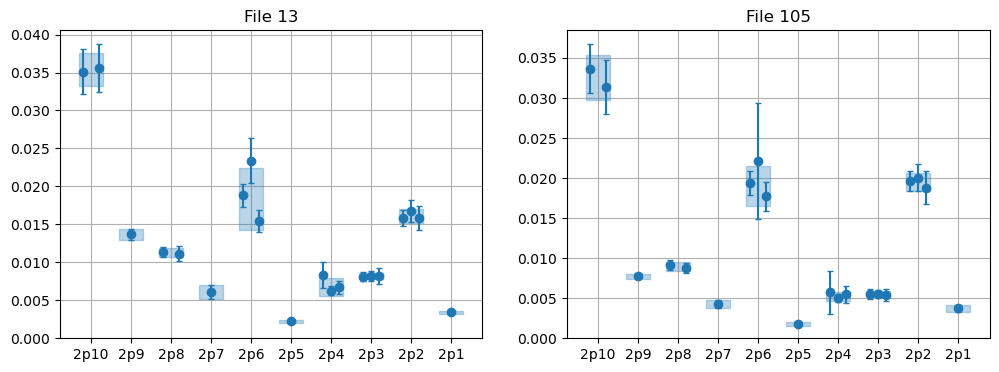

In [53]:
splt.init_bytot( len( data ), cols = 2 )
for d in data:
    splt.next()

    for (k,v) in d['densities'].items():
        i = lv.ID( k )
        plt.fill_between( [ i - 0.3, i + 0.3 ], np.array([1,1]) * v['avg'].n - v['avg'].s, np.array([1,1]) *  v['avg'].n + v['avg'].s, color = 'tab:blue', alpha = 0.3 )
        xs = np.linspace( i - 0.2, i + 0.2, len( v['all'] ) )
        if( len( v['all'] ) == 1 ):
            xs = [ i ]
        plt.plot( xs, v['all'], fmt = 'o', color = 'tab:blue' )

    plt.xticks( np.arange( 5, 15 ), [ lv.name( i ) for i in range( 5,15 ) ] )
    plt.ylim( bottom = 0 )

    plt.title(f"File {d['ID']}")